# **1. AI Agent**

- LLM(Large Language Model): 사용자의 입력을 읽고 문장을 생성하는 언어 모델. 단독으로는 일반적으로 외부 웹사이트 검색, 파일 수정, 실제 예약을 실행하지 않음
- AI Agent(인공지능 에이전트): 목표를 달성하기 위해 현재 상태/환경을 관찰하고, 다음 행동을 결정하고, 필요한 도구를 사용한 뒤 결과를 다시 확인하는 시스템
- LLM 기반 Agent: LLM을 의사결정 구성요소로 활용하고 도구와 실행 제어를 결합한 Agent

```
예시
"서울 날씨가 비가 온다면 우산을 챙기라고 알려줘."

1. 목표: 비 여부에 따른 안내가 필요
2. 도구 선택: 날씨 조회 도구가 필요
3. 도구 실행: 날씨 API가 실제 관측/예보 정보를 반환
4. 결과 해석: 비가 예상되는지 확인
5. 응답: 우산을 챙기라는 안내 또는 필요 없다는 안내를 생성
```

> 모든 Agent가 LLM을 사용하는 것은 아님. 로봇청소기나 게임 AI도 넓은 의미의 Agent가 될 수 있음

### Agent의 구성요소
- 목표: 무엇을 달성해야 하는가?
- Model/Policy: 다음 행동을 어떻게 선택하는가?
- Tools: 검색, 계산, DB 조회, API 요청 등 실제 작업을 수행
- Memory: 실행 중 대화 이력 또는 장기 저장된 정보를 활용
- State: 질문, 결과, 현재 단계 등을 담음
- 평가: 권한, 승인, 종료 조건, 결과 품질을 점검

### 그래프(Graph)
그래프는 노드와 엣지로 구성된 연결 구조
- 노드: 사람, 작업처럼 하나의 대상 또는 처리 단위
- 엣지: 두 노드 사이의 관계 또는 이동 경로
- 방향 그래프: A > B 처럼 방향이 있음
- 사이클: A > B > A 처럼 다시 돌아오는 경로가 있음

> LangGraph에서는 노드를 "실행할 함수", 엣지를 "다음에 실행할 노드로 이동하는 규칙"으로 사용

```
예
START > 질문 분석 > 답변 생성 > END
      >   검색   >
```

# **2. 랭그래프**
- LangChain 생태계에서 에이전트나 RAG 시스템을 단계별로 구성하고 실행할 수 있게 해주는 그래프 기반 오케스트레이션 프레임워크
- 기존 RAG가 직선형 파이프라인이었다면, 랭그래프는 노드(작업 단위)와 엣지(흐름)를 그래프 형태로 정의해 분기, 반복, 조건 처리, 에이전트 루프 같은 복잡한 흐름을 명확하게 표현하고 실행

### 랭체인
- LangChain은 대형 언어 모델을 활용한 애플리케이션을 쉽게 개발할 수 있도록 다양한 기능을 제공하는 프레임워크
- 프롬프트 관리, 문서 검색, 벡터 데이터베이스 연동, 체인 구조를 통한 여러 작업의 연결, 그리고 외부 도구 사용 등을 하나의 흐름으로 구성할 수 있게 해줌
- 챗봇, 문서 기반 질의응답(RAG), 에이전트 시스템과 같은 AI 서비스를 효율적으로 구축

### 랭그래프의 구성요소

1. 노드(Node)
- 노드는 LangGraph 워크플로우 안에서 실행되는 개별 작업 단위
- 예) "질문을 임베딩하기", "벡터DB에서 관련 문서 검색하기", "LLM으로 답변 생성하기" 같은 단계가 각각 하나의 노드가 됨
- 노드는 전체 워크플로우를 이루는 핵심 블록

2. 엣지(Edge)
- 엣지는 노드와 노드를 연결하는 흐름을 의미
- 한 노드의 결과가 다음 노드의 입력으로 이어지도록 만들어주며, 워크플로우가 순차적으로 진행할 수 있게 함

3. 상태(State)
- 상태는 워크플로우 실행 중 유지되고 공유되는 데이터 저장소
- 사용자 질문, 검색 결과, 현재까지의 답변 초안 등이 상태에 담겨 각 노드가 읽고 쓸 수 있음
- 상태 덕분에 그래프 전체가 일관된 맥락을 유지할 수 있음

- TypedDict: 파이썬의 typing 모듈에서 제공하며, 딕셔너리의 키와 값의 타입을 정의
- BaseModel: Pydantic 라이브러리에서 제공

In [10]:
from typing import TypedDict

In [2]:
class User(TypedDict):
    id: int
    name: str
    email: str

In [3]:
user1: User = {'id': 1, "name": "김사과", "email": "apple@apple.com"}
user1

{'id': 1, 'name': '김사과', 'email': 'apple@apple.com'}

In [4]:
user2: User = {'id': 2, "name": 1000, "email": "apple@apple.com"}
user2

{'id': 2, 'name': 1000, 'email': 'apple@apple.com'}

In [5]:
from pydantic import BaseModel

In [6]:
class User(BaseModel):
    id: int
    name: str
    email: str

In [7]:
user1: User = {'id': 1, "name": "김사과", "email": "apple@apple.com"}
user1

{'id': 1, 'name': '김사과', 'email': 'apple@apple.com'}

In [8]:
user2: User = {'id': 2, "name": 1000, "email": "apple@apple.com"}
user2

{'id': 2, 'name': 1000, 'email': 'apple@apple.com'}

In [11]:
user3: User = {'id': "3", "name": 1000, "email": "apple@apple.com"}
user3

{'id': '3', 'name': 1000, 'email': 'apple@apple.com'}

In [12]:
from langgraph.graph import StateGraph, START, END

In [13]:
class HelloState(TypedDict):
    name: str
    greeting: str

def greeting_node(state: HelloState):
    return {"greeting": f"안녕하세요, {state['name']}님!"}

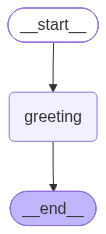

In [17]:
hello_builder = StateGraph(HelloState)
hello_builder.add_node("greeting", greeting_node)
hello_builder.add_edge(START, "greeting")
hello_builder.add_edge("greeting", END)
hello_graph = hello_builder.compile()
hello_graph

In [18]:
print(hello_graph.invoke({"name":"김사과", "greeting":""}))

{'name': '김사과', 'greeting': '안녕하세요, 김사과님!'}


In [19]:
from typing import Annotated
import operator

In [22]:
a = 10
b = 20
print(operator.add(a, b))

30


In [ ]:
class HistoryState(TypedDict):
    # Annotated: 기존 타입에 추가적인 정보를 붙일 수 있는 기능
    # operator.add: 병합함수. 예) operator.add(a, b)는 a+B 연산을 수행
    history: Annotated[list[str], operator.add]

def first_note(state: HistoryState):
    return {"history": ["1단계"]}

def second_note(state: HistoryState):
    return {"history": ["2단계"]}

In [21]:
history_builder = StateGraph(HistoryState)
history_builder.add_node("first", first_note)
history_builder.add_node("second", second_note)
history_builder.add_edge(START, "first")
history_builder.add_edge("first", "second")
history_builder.add_edge("second", END)
history_graph = history_builder.compile()

In [23]:
print(history_graph.invoke({"history": []}))

{'history': ['1단계', '2단계']}


In [ ]:
from langgraph.graph import MessagesState
from langchain_core.messages import HumanMessage, AIMessage

In [26]:
# HumanMessage: 사용자가 AI에게 메시지를 전달할때 사용하는 함수
# AIMessage: AI가 사용자에게 메세지를 전달할때 사용

classroom_messages = {"messages": [HumanMessage(content="안녕하세요!"), AIMessage(content="반갑습니다!")]}
print([(m.type, m.content) for m in classroom_messages['messages']])

[('human', '안녕하세요!'), ('ai', '반갑습니다!')]


In [27]:
from typing import Literal

In [28]:
class GradeState(TypedDict):
    score: int
    result: str

def check_grade(state: GradeState):
    return {}

def pass_grade(state:GradeState):
    return{"result": "합격"}

def fail_grade(state:GradeState):
    return{"result": "재시험"}

def grade_route(state:GradeState) -> Literal["pass", 'fail']:
    return "pass" if state["score"] >= 60 else "fail"

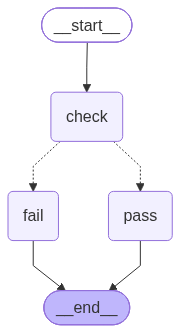

In [29]:
grade_builder = StateGraph(GradeState)
grade_builder.add_node("check", check_grade)
grade_builder.add_node("pass", pass_grade)
grade_builder.add_node("fail", fail_grade)
grade_builder.add_edge(START, "check")
grade_builder.add_conditional_edges("check", grade_route)
grade_builder.add_edge("pass", END)
grade_builder.add_edge("fail", END)
grade_graph = grade_builder.compile()
grade_graph

In [38]:
class CountState(TypedDict):
    count: int

def increase_count(state: CountState):
    return {"count": state["count"] + 1}

def count_route(state: CountState) -> Literal["increase", "__end__"]:
    return "increase" if state["count"] < 3 else END

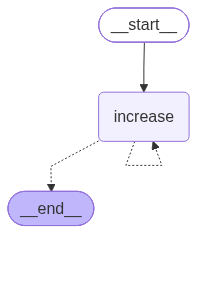

In [39]:
count_builder = StateGraph(CountState)
count_builder.add_node("increase", increase_count)
count_builder.add_edge(START, "increase")
count_builder.add_conditional_edges("increase", count_route)
count_graph = count_builder.compile()
count_graph

In [40]:
print(count_graph.invoke({"count": 0}, config={"recursion_limit": 10}))

{'count': 3}


In [41]:
class MultiState(TypedDict):
    results: Annotated[list[str], operator.add]

def left_task(state: MultiState):
    return {"results": ["왼쪽 작업"]}

def right_task(state: MultiState):
    return {"results": ["오른쪽 작업"]}

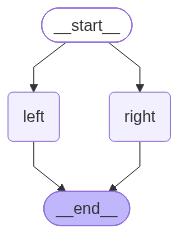

In [42]:
multi_builder = StateGraph(MultiState)
multi_builder.add_node("left", left_task)
multi_builder.add_node("right", right_task)
multi_builder.add_edge(START, "left")
multi_builder.add_edge(START, "right")
multi_builder.add_edge("left", END)
multi_builder.add_edge("right", END)
multi_graph = multi_builder.compile()
multi_graph

In [43]:
print(multi_graph.invoke({"results": []}))

{'results': ['왼쪽 작업', '오른쪽 작업']}


# **3. Tool**

In [44]:
from langchain_core.tools import tool

In [45]:
@tool
def add_numbers(a: int, b: int) -> int:
    """두 정수를 더합니다."""
    return a + b

@tool
def multiply_numbers(a: int, b: int) -> int:
    """두 정수를 곱합니다."""
    return a * b

In [ ]:
# tool은 invoke함수로 불러와서 사용할 수 있음

print(add_numbers.invoke({"a": 10, "b": 5}))
print(multiply_numbers.invoke({"a": 3, "b": 4}))

15
12


In [52]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

In [53]:
load_dotenv()

True

In [ ]:
API_KEY = os.getenv("OPENAI_API_KEY")
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
# 모델에 따라서 불러줘야하는 값들이 다르므로 확인해야함
# gpt-5.6-luna용 설정: api_key=API_KEY, temperature=0, reasoning_effort="none"
# reasoning_effort: 추론 노력 수준. none: 빠른 응답에 유리, low: 간단한 판단, medium: 일반적인 복잡한 문제, high: 복잡한 분석 및 문제 해결
llm = ChatOpenAI(model=MODEL_NAME, api_key=API_KEY, temperature=0, reasoning_effort="none") if API_KEY else None
print("LLM 로딩:", bool(llm), "모델:", MODEL_NAME)

LLM 로딩: True 모델: gpt-5.6-luna


- 일반적으로 툴의 사용은 LLM이 판단해서 결정
- tool_choice 옵션: 툴 사용의 결정을 설정
    - auto: LLM이 사용 여부 판단(기본값)
    - required: 최소 하나의 도구 호출 요청
    - none: 도구 호출 금지

In [59]:
if llm is not None:
    tool_llm = llm.bind_tools([add_numbers, multiply_numbers])
    request = tool_llm.invoke("3 곱하기 12와 11 더하기 49를 계산해줘")
    print("도구 호출 요청:", request.tool_calls)
else:
    print("OPENAI_API_KEY 에러")

도구 호출 요청: [{'name': 'multiply_numbers', 'args': {'a': 3, 'b': 12}, 'id': 'call_PkZ7pLCDHWxPKizxhXR76bst', 'type': 'tool_call'}, {'name': 'add_numbers', 'args': {'a': 11, 'b': 49}, 'id': 'call_ywFD5OBoM14hwYJXUdnggO6X', 'type': 'tool_call'}]


In [60]:
if llm is not None:
    tool_llm = llm.bind_tools([add_numbers, multiply_numbers], tool_choice="none")
    request = tool_llm.invoke("3 곱하기 12와 11 더하기 49를 계산해줘")
    print("도구 호출 요청:", request.tool_calls)
else:
    print("OPENAI_API_KEY 에러")

도구 호출 요청: []


In [61]:
from langgraph.prebuilt import ToolNode, tools_condition

In [65]:
if llm is not None:
    agent_llm = llm.bind_tools([add_numbers, multiply_numbers])
    def agent_step(state: MessagesState):
        return{"messages": [agent_llm.invoke(state["messages"])]}
    agent_builder = StateGraph(MessagesState)
    agent_builder.add_node("agent", agent_step)
    agent_builder.add_node("tools", ToolNode([add_numbers, multiply_numbers]))
    agent_builder.add_edge(START, "agent")
    agent_builder.add_conditional_edges("agent", tools_condition)
    agent_builder.add_edge("tools", "agent")
    tools_agent_graph = agent_builder.compile()
    result = tools_agent_graph.invoke({"messages": [{"role": "user", "content": "37 곱하기 21은?"}]}, config={"recursion_limit": 10})
    print(result["messages"][-1].content)
else:
    print("API키 에러")

37 × 21 = **777**


In [66]:
result["messages"]

[HumanMessage(content='37 곱하기 21은?', additional_kwargs={}, response_metadata={}, id='882267d8-832b-4ff5-ab37-76b23e3407e2'),
 AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 21, 'prompt_tokens': 161, 'total_tokens': 182, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EeZfD4zCa7rRWtzTleLBaZBOvhLfd', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a18b54-45a7-7103-95e4-24bf8595b31e-0', tool_calls=[{'name': 'multiply_numbers', 'args': {'a': 37, 'b': 21}, 'id': 'call_DR0OhIMlZ0mIXlUHAvBeez2K', 'type': 'tool_call'}], invalid_tool_calls=[],

```
HumanMessage = "37 곱하기 21은?"
AIMessage > multiply_numbers 호출 요청
ToolMessage > 37 * 21 = 777
AIMessage = "777입니다."
```

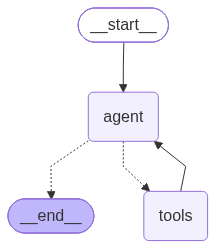

In [ ]:
tools_agent_graph
# 점선은 conditional_edge

In [ ]:
from langchain.agents import create_agent     # pip install langchain

In [69]:
if llm is not None:
    ready_agent = create_agent(model=llm, tools=[add_numbers, multiply_numbers], system_prompt="계산에는 반드시 계산 도구를 사용하고 영어로 답하세요")
    answer = ready_agent.invoke({"messages": [{"role": "user", "content": "123과 456을 더해줘"}]})
    print(answer["messages"][-1].content)
else:
    print("API키 오류")

123 + 456 = **579**


### Structured Output
- 자유로운 문장 대신 필드가 고정된 객체를 반환하도록 요청
- 웹서비스/API/DB 저장에 유리

In [70]:
from pydantic import Field

In [71]:
class LessonSummary(BaseModel):
    topic: str = Field(description="학습 주제")
    keywords: list[str] = Field(description="핵심 키워드")
    difficulty: int = Field(ge=1, le=5, description="난이도 1~5")

if llm is not None:
    structured = llm.with_structured_output(LessonSummary)
    print(structured.invoke("LangGraph 상태 관리 수업에 대해 요약해줘"))
else:
    print(LessonSummary(topic="LangGraph", keywords=["State", "Node", "Edge"], difficulty=2))

topic='LangGraph 상태 관리' keywords=['StateGraph', '상태(State)', '노드(Node)', '엣지(Edge)', '상태 스키마', 'Reducer', '체크포인트', '메모리', '상태 업데이트'] difficulty=3
